# DiffusionCB — Step 5: discriminability analysis

Reads the labelled CB runs from `data/*.parquet` and asks the paper's core question:
**does the raw (un-averaged) data separate the 3 noise classes where the standard
CB number λ_P cannot?**

Fingerprints, in order: **5a** averaged view `F_{P,m}` + λ_P (the baseline) ·
**5b** spread across sequences `Var_l(f)` · **5c** cross-Pauli structure · **5d** verdict.

### Loop structure — one `(class, param, seed)` run = 3 × 6 × 30 = 540 rows

```text
for P in [X, Y, Z]:                 ← 3 Paulis      (outer)
    for m in [2,4,6,8,12,16]:       ← 6 lengths     (middle)
        for l in range(30):         ← 30 sequences  (inner)
            → run_once → one circuit → 1024 shots → ONE f value
```

5a and 5b collapse **only the inner (L) loop** at each `(P, m)` bucket:
mean → `F` (5a), variance → `Var_l(f)` (5b). `P` and `m` stay as labels (18 buckets).

### λ_P at param = 0.10 — memory vs jitter are *closely matched* (~0.03 apart)

| class  |  X   |   Y   |   Z   |
|--------|:----:|:-----:|:-----:|
| memory | 0.98 | 0.934 | 0.920 |
| jitter | 0.98 | 0.904 | 0.890 |

λ (the standard CB number) barely differs between the two — yet 5b's spread pulls them
apart. That gap between "same λ" and "different spread" is the whole thesis.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# load all labelled runs into one long-format dataframe
DATA_DIR = Path("data")
files  = sorted(DATA_DIR.glob("*.parquet"))
df_all = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(f"loaded {len(files)} files, {len(df_all)} rows")
df_all.head()

loaded 450 files, 243000 rows


,noisetype,param,param_value,seed,P,m,l,f_pml,n_plus,n_minus,pauli_sign,twirl_seq
0,drift,eps,0.05,0,X,2,0,1.0,0,1024,-1,"[Z, Y, Y]"
1,drift,eps,0.05,0,X,2,1,1.0,1024,0,1,"[X, X, I]"
2,drift,eps,0.05,0,X,2,2,1.0,1024,0,1,"[I, I, I]"
3,drift,eps,0.05,0,X,2,3,1.0,0,1024,-1,"[Z, Y, Z]"
4,drift,eps,0.05,0,X,2,4,1.0,0,1024,-1,"[Y, Y, Z]"


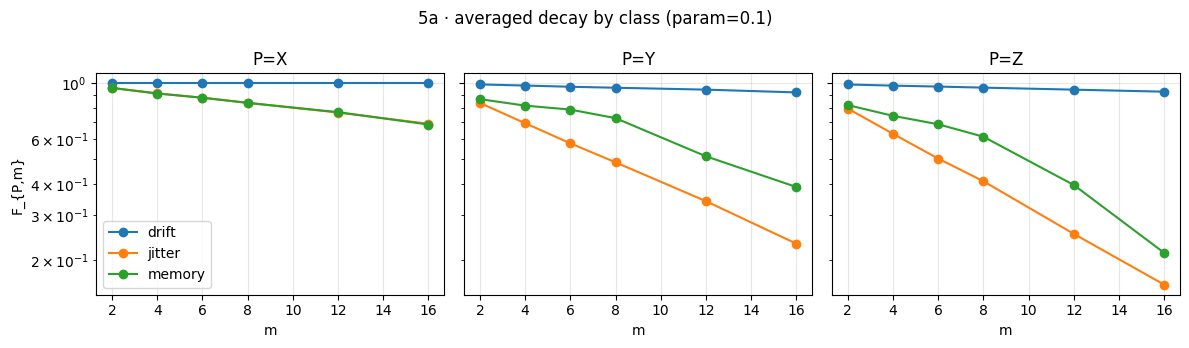

In [3]:
# 5a — averaged view F_{P,m}  (the baseline: exactly what standard CB sees)
F = (df_all.groupby(["noisetype", "param_value", "P", "m"])["f_pml"]
            .mean().reset_index(name="F"))

pval   = 0.10                              # compare the 3 classes at one dial setting
paulis = sorted(F.P.unique())
fig, axes = plt.subplots(1, len(paulis), figsize=(4*len(paulis), 3.5), sharey=True)
for ax, P in zip(axes, paulis):
    for cls, g in F[(F.P == P) & (F.param_value == pval)].groupby("noisetype"):
        g = g.sort_values("m")
        ax.plot(g.m, g.F, "o-", label=cls)
    ax.set_yscale("log"); ax.set_title(f"P={P}"); ax.set_xlabel("m"); ax.grid(alpha=.3)
axes[0].set_ylabel("F_{P,m}"); axes[0].legend()
fig.suptitle(f"5a · averaged decay by class (param={pval})")
plt.tight_layout(); plt.show()


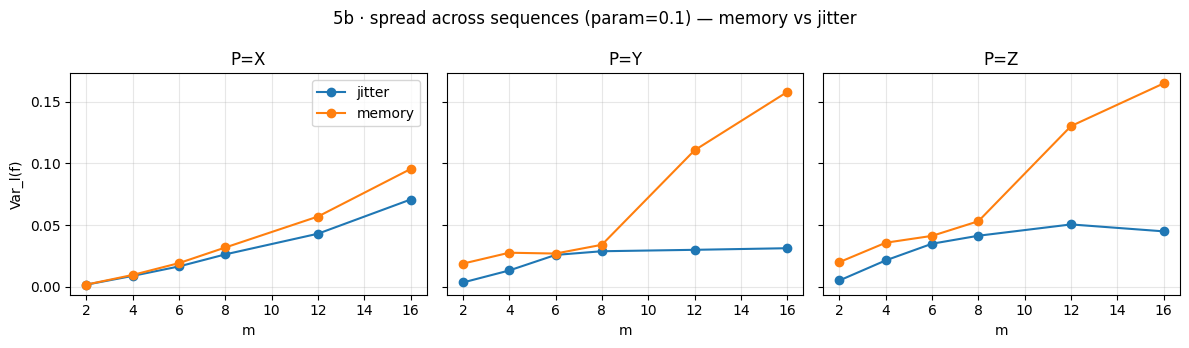

In [4]:
# 5b — variances view F_{P,m}  (the baseline: exactly what standard CB sees)
var_F = (df_all.groupby(["noisetype", "param_value", "P", "m"])["f_pml"]
            .var().reset_index(name="var"))

# 5b plot — spread Var_l(f) vs m, memory vs jitter at matched λ (param=0.10)
pval    = 0.10
compare = ["memory", "jitter"]                 # the matched-λ pair (drift not matched yet)
paulis  = sorted(var_F.P.unique())
fig, axes = plt.subplots(1, len(paulis), figsize=(4*len(paulis), 3.5), sharey=True)
for ax, P in zip(axes, paulis):
    sub = var_F[(var_F.P == P) & (var_F.param_value == pval)
                & (var_F.noisetype.isin(compare))]
    for cls, g in sub.groupby("noisetype"):
        g = g.sort_values("m")
        ax.plot(g.m, g["var"], "o-", label=cls)
    ax.set_title(f"P={P}"); ax.set_xlabel("m"); ax.grid(alpha=.3)
axes[0].set_ylabel("Var_l(f)"); axes[0].legend()
fig.suptitle(f"5b · spread across sequences (param={pval}) — memory vs jitter")
plt.tight_layout(); plt.show()



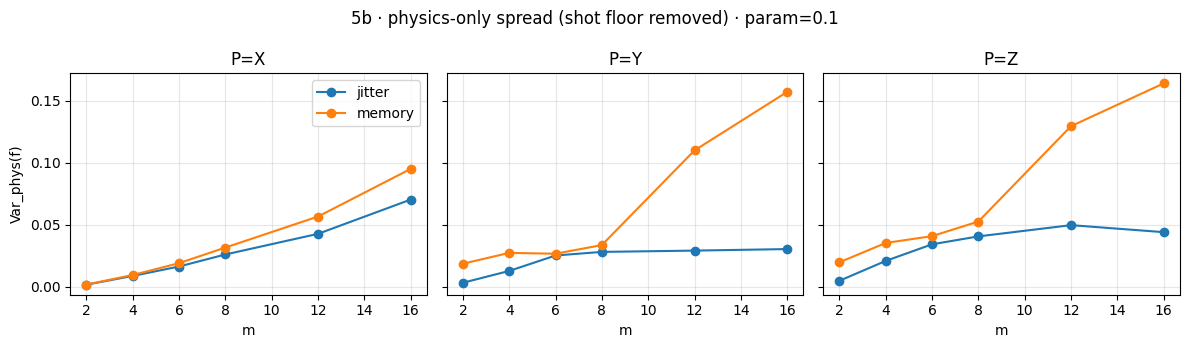

In [5]:
df_all["shots"] = df_all.n_plus + df_all.n_minus
df_all["shot_var"] = 4 * df_all.n_plus*df_all.n_minus / df_all.shots**3  # variance of f = (n_+ - n_-)/shots

g = ["noisetype", "param_value", "P", "m"]
var_obs  = df_all.groupby(g)["f_pml"].var() 
floor = df_all.groupby(g)["shot_var"].mean()  # mean of the shot noise variance
var_phys = (var_obs - floor).reset_index(name="var_phys")
var_phys["var_obs"] = var_obs.values              # keep both, to see the floor barely moves it
var_phys["floor"]   = floor.values
var_phys.tail()

# 5b (final) — physics-only spread (shot floor removed), memory vs jitter at matched λ
pval    = 0.10
compare = ["memory", "jitter"]
paulis  = sorted(var_phys.P.unique())
fig, axes = plt.subplots(1, len(paulis), figsize=(4*len(paulis), 3.5), sharey=True)
for ax, P in zip(axes, paulis):
    sub = var_phys[(var_phys.P == P) & (var_phys.param_value == pval)
                   & (var_phys.noisetype.isin(compare))]
    for cls, grp in sub.groupby("noisetype"):
        grp = grp.sort_values("m")
        ax.plot(grp.m, grp.var_phys, "o-", label=cls)
    ax.set_title(f"P={P}"); ax.set_xlabel("m"); ax.grid(alpha=.3)
axes[0].set_ylabel("Var_phys(f)"); axes[0].legend()
fig.suptitle(f"5b · physics-only spread (shot floor removed) · param={pval}")
plt.tight_layout(); plt.show()



matched param per class: {'drift': 0.4, 'jitter': 0.1, 'memory': 0.1}


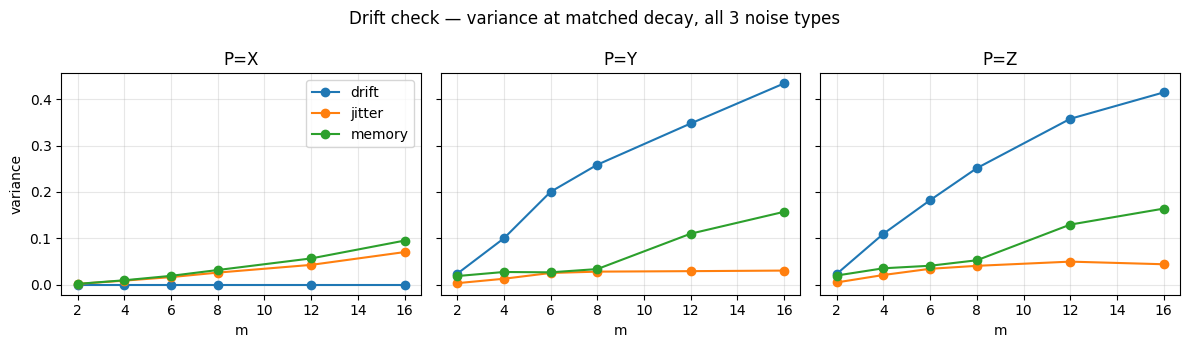

In [6]:
# generated additional data for drift now lets compare all 3 noise types at matched λ (param=0.10)

# 1) Measure how much each run "decayed".
#    - Every run gives a survival number F at each sequence length m.
#      F near 1 = signal barely faded; F near 0 = signal mostly gone.
#    - We look only at the LONGEST sequence (m = 16), because that's where
#      the noise types differ the most.
#    - We use only the Y and Z measurements (X barely moves, so it's not useful).
#    - We average Y and Z into one number per run.
#    Result: `decay` = one number per (noise type, dial setting) =
#            "how much signal is left at the end". Low = decayed a lot.
big_m = F.m.max()
decay = (F[(F.m == big_m) & F.P.isin(["Y", "Z"])]
         .groupby(["noisetype", "param_value"])["F"].mean().reset_index(name="decay"))

# 2) Pick a "target" decay level that ALL three noise types can reach.
#    - Each noise type covers a RANGE of decay as you turn its dial:
#      from its most-decayed run (min) to its least-decayed run (max).
#    - mins.max() = the highest floor  → as low as all three can commonly go.
#    - maxs.min() = the lowest ceiling → as high as all three can commonly go.
#    - The band between them is the decay level every type can produce.
#    - target = the middle of that shared band (a safe, central level to match 
# on).
#memory  : [0.15 ──────────────── 0.60]
#jitter  : [0.10 ────────────── 0.55]
#drift   :        [0.20 ─────────────────── 0.90]
#                  ↑                    ↑
#              highest floor       lowest ceiling
mins, maxs = decay.groupby("noisetype")["decay"].min(), decay.groupby("noisetype")["decay"].max()
target = (mins.max() + maxs.min()) / 2

# 3) For each noise type, pick the dial setting that matches the target decay.
#    - Go through each noise type (memory, jitter, drift) one at a time.
#    - Look at all its dial settings and how much each one decayed.
#    - Find the dial whose decay is closest to the target we chose in step 2.
#    - Store that dial in `matched`, so we end up with one chosen setting per type.
#    Result: matched = {"memory": 0.10, "jitter": 0.10, "drift": 0.40} (or similar).
matched = {}
for noisetype in decay["noisetype"].unique():                 # noise = memory / jitter / drift
    rows    = decay[decay.noisetype == noisetype]             # this type's rows
    closest = (rows.decay - target).abs().idxmin()        # row nearest the target
    matched[noisetype] = rows.loc[closest, "param_value"]     # its dial setting
print("matched param per class:", matched)


# 4) Plot the variance vs sequence length for all 3 noise types,
#    each at its matched dial (from step 3).
#    - One panel per Pauli (X, Y, Z).
#    - In each panel, one line per noise type.
#    If the lines separate, the raw-data variance can tell the noise types apart.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, P in zip(axes, ["X", "Y", "Z"]):
    for noisetype, param_value in matched.items():                        # noise + its matched dial
        rows = var_phys[(var_phys.noisetype == noisetype) &
                        (var_phys.param_value == param_value) &
                        (var_phys.P == P)].sort_values("m")
        ax.plot(rows.m, rows.var_phys, "o-", label=noisetype)
    ax.set_title(f"P={P}"); ax.set_xlabel("m"); ax.grid(alpha=.3)
axes[0].set_ylabel("variance"); axes[0].legend()
plt.suptitle("Drift check — variance at matched decay, all 3 noise types")
plt.tight_layout(); plt.show()
